# Automated parameter selection

The model has 37 kinetic parameters, and 22 conditions of steady-state data cannot determine them all. The selection
builds an **identifiable parameter structure**: it starts with all 37 parameters free (*stage 0*) and fixes parameters
one at a time, at their estimated values, until the free set passes the identifiability criteria. Every step is
automatic and deterministic. Code: `src/selection.py`, `src/identifiability/`, `src/estimation/refit.py`; settings:
`settings/method.csv`.

**Stage 0.** Weighted least squares with all 37 parameters free, from the literature values and `n_starts`
log-uniform random starts in the parameter bounds (multistart); the best start is refined.

**Step 1, structural identifiability** (Stigter and Molenaar, 2015). At `structural_q` random parameter vectors the
exact sensitivities of the 9 reaction rates at the fitted states (CasADi automatic differentiation), in
log-parameters, are stacked into one matrix $S$. A singular value of $S$ below `structural_tol` times the largest is a
structural zero: a direction of the parameters that no rate can see. The rule below acts on it; then one refit.

**Step 2, practical identifiability** (one decision per iteration). With $G = \partial y^*/\partial\theta$ the
sensitivities of the measured outputs of the fitted model (implicit function theorem on the optimality conditions of
each condition, exact derivatives from CasADi), $J = Q^{-1/2} G\,\mathrm{diag}(\theta)$ and the Fisher information
$F = J^\top J$:

1. if $\sigma_\min(J)/\sigma_\max(J) <$ `rank_tol`, $F$ is rank deficient: the rule acts on the parameter with the
   largest loading in the singular vector of $\sigma_\min$;
2. else, in the pair with the largest $|r_{ij}| >$ `corr_threshold` ($r$ from $F^{-1}$), the more sensitive member
   stays free and the rule acts on the other; the sensitivity of a parameter is the mean of the normalized sensitivity
   coefficients $|\partial\ln y^*/\partial\ln\theta|$ over the conditions and measured outputs (entries of outputs
   below 1% of their median are left out, because the relative sensitivity diverges near zero);
3. else the free set is identifiable and the selection stops.

**Rule.** The parameter is fixed at its estimated value and the model is refitted (warm started; the previous fit is
kept if the refit is not better). A rate law always keeps one free parameter (and the prefixes of
`settings/protected_params.csv` are never fixed): a protected parameter is instead reported as not identifiable
("kept free by design") and left out of the later criteria.

In [1]:
import os
import sys
import json
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])
RUN = os.environ.get("HK_RUN", "0") == "1"

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("OUT :", OUT)
print("RUN :", RUN, "(False: load the saved results of OUT; True: compute and save into OUT)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

import selection
from model.parameters import ALL_PARAMS, RXN_OF_PARAM

STAGE0 = os.path.join(OUT, "stage0")
RED = os.path.join(OUT, "reduction")

OUT : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model
RUN : False (False: load the saved results of OUT; True: compute and save into OUT)


In [2]:
# Settings of the method (defaults from settings/method.csv)
params = settings.default_params()
params["n_jobs"] = int(os.environ.get("HK_N_JOBS", params["n_jobs"]))
params

{'n_starts': 50,
 'seed': 0,
 'structural_q': 10,
 'structural_tol': 1e-10,
 'rank_tol': 0.0001,
 'corr_threshold': 0.9,
 'lr_alpha': 0.95,
 'bootstrap_n': 5000,
 'bootstrap_ci_ratio': 10.0,
 'bootstrap_local_starts': 5,
 'bootstrap_local_span': 1.0,
 'profile_points': 30,
 'profile_span': 1.0,
 'profile_extra_starts': 3,
 'profile_extra_span': 1.0,
 'bootstrap_profile_seeds': 3,
 'n_jobs': 10,
 'out_dir': 'results/flux_model'}

## 1. Run (`HK_RUN=1`)

`selection.run_selection` writes `OUT/stage0/` (multistart table, stage-0 fit) and `OUT/reduction/` (fixing log,
iterations, final fit). `HK_FROM_ANCHOR=<dir with anchor_state.pkl>` skips stage 0.

In [3]:
if RUN:
    selection.run_selection(OUT, params, from_anchor=os.environ.get("HK_FROM_ANCHOR"))
else:
    print("RUN is False: the selection is loaded from", OUT)

RUN is False: the selection is loaded from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model


## 2. Stage 0: multistart with all 37 parameters free

In [4]:
stage0 = json.load(open(os.path.join(STAGE0, "stage_row.json")))
multistart = pd.read_csv(os.path.join(STAGE0, "multistart_recorded.csv"))
print("stage 0: obj %.4f; multistart %d/%d converged, best %.4f, median %.4f" % (
    stage0["obj"], stage0["multistart_n_converged"], stage0["multistart_n_total"], stage0["multistart_best_table"],
    stage0["multistart_median"]))

stage 0: obj 11.7455; multistart 47/51 converged, best 12.3244, median 76.0793


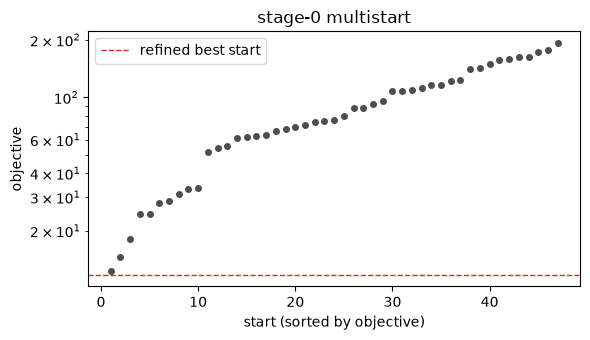

In [5]:
converged = multistart[multistart["converged"]].sort_values("obj_value").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(converged) + 1), converged["obj_value"], "o", color="0.3", ms=4)
ax.axhline(stage0["obj"], color="tab:red", ls="--", lw=1, label="refined best start")
ax.set_yscale("log")
ax.set_xlabel("start (sorted by objective)")
ax.set_ylabel("objective")
ax.legend()
ax.set_title("stage-0 multistart")
fig.tight_layout()
plt.show()

## 3. Fixing path

One row per decision: the stage (structural / practical), the rule (structural zero, SVD, correlation), the action
(fixed / kept free by design), the loading or the correlated partner, and the objective after the refit.

In [6]:
fixes = pd.read_csv(os.path.join(RED, "fixing_log.csv"))
fixes["reaction"] = fixes["param"].map(RXN_OF_PARAM)
fixes[["iter", "stage", "rule", "param", "reaction", "action", "loading", "partner", "r", "sensitivity", "value", "obj_after"]].round(4)

,iter,stage,rule,param,reaction,action,loading,partner,r,sensitivity,value,obj_after
0,0,structural,structural_zero,Ks_nad_6,gap,fixed,-0.5448,NaN,NaN,NaN,0.0050,10.9087
1,0,structural,structural_zero,Ks_pgp_7,pgk,fixed,-0.6845,NaN,NaN,NaN,0.0012,10.9087
2,0,structural,structural_zero,Kp_pgp_6,gap,fixed,0.7066,NaN,NaN,NaN,2.8495,10.9087
3,0,structural,structural_zero,Ks_3pg_7,pgk,fixed,0.7010,NaN,NaN,NaN,3.6545,10.9087
4,0,structural,structural_zero,Ks_g3p_6,gap,fixed,0.6604,NaN,NaN,NaN,0.0050,10.9087
5,0,structural,structural_zero,Kp_fbp_3,pfk,fixed,-0.6172,NaN,NaN,NaN,0.0021,10.9087
6,0,structural,structural_zero,Kp_g3p_4,fba,fixed,0.7071,NaN,NaN,NaN,5.5390,10.9087
7,0,structural,structural_zero,Ks_f6p_3,pfk,fixed,0.7071,NaN,NaN,NaN,0.9724,10.9087
8,1,practical,svd,Kp_nadh_6,gap,fixed,-1.0000,NaN,NaN,0.0000,10.0005,10.9087
9,2,practical,svd,Kp_g3p_5,tpi,fixed,-1.0000,NaN,NaN,0.0000,10.0013,10.9087


In [7]:
iterations = pd.read_csv(os.path.join(RED, "iterations.csv"))
iterations

,iter,n_free,n_analysed,obj,sigma_ratio_min,full_rank,max_abs_r,n_pairs,sens_failed_conditions,decision
0,1,29,29,10.908666,1.718591e-16,False,NaN,0,KO04,fixed Kp_nadh_6 (svd)
1,2,28,28,10.908666,1.083477e-11,False,NaN,0,KO04,fixed Kp_g3p_5 (svd)
2,3,27,27,10.908666,1.971196e-10,False,NaN,0,KO04,fixed Ka1_1 (svd)
3,4,26,26,10.908666,3.118239e-10,False,NaN,0,KO04,fixed K_g6p_1 (svd)
4,5,25,25,10.908666,5.766902e-09,False,NaN,0,KO04,fixed Ks_atp_7 (svd)
5,6,24,24,10.908666,8.849091e-09,False,NaN,0,KO04,fixed Ka3_1 (svd)
6,7,23,23,10.908666,1.001587e-08,False,NaN,0,KO04,fixed Kp_f6p_pgi (svd)
7,8,22,22,10.908666,5.813463e-08,False,NaN,0,KO04,fixed Kp_dhap_4 (svd)
8,9,21,21,10.908666,2.027192e-07,False,NaN,0,KO04,fixed Ks_2pg_8 (svd)
9,10,20,20,10.908666,4.328465e-07,False,NaN,0,KO04,fixed Ks_pi_6 (svd)


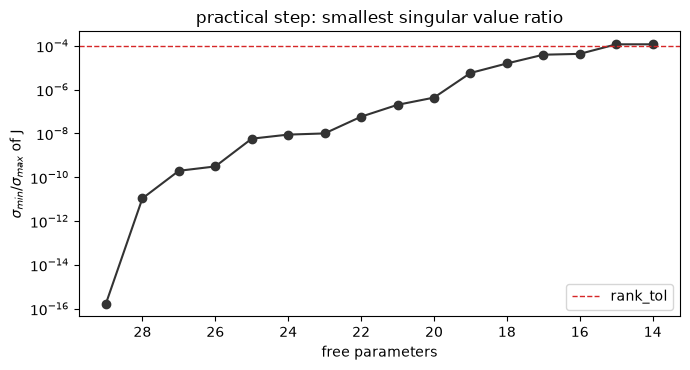

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(iterations["n_free"], iterations["sigma_ratio_min"], "o-", color="0.2")
ax.axhline(params["rank_tol"], color="tab:red", ls="--", lw=1, label="rank_tol")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("free parameters")
ax.set_ylabel(r"$\sigma_{min} / \sigma_{max}$ of J")
ax.legend()
ax.set_title("practical step: smallest singular value ratio")
fig.tight_layout()
plt.show()

## 4. Selected structure

In [9]:
summary = json.load(open(os.path.join(RED, "reduction_summary.json")))
print("%d free: %s" % (summary["n_free"], ", ".join(summary["free"])))
print("kept free by design:", summary["kept_free_by_design"] or "none")
print("objective %.5f (stage 0 %.5f); wall %.0f s" % (summary["obj"], stage0["obj"], summary["wall_s"]))

14 free: v_max_1, Ks_g6p_pgi, kcat_f_2, kcat_f_3, Ks_fbp_4, kcat_f_4, kcat_f_5, kcat_f_6, kcat_f_7, Ks_adp_7, kcat_f_8, Ks_3pg_8, kcat_f_9, Ks_2pg_9
kept free by design: none
objective 10.90867 (stage 0 11.74548); wall 102 s
